# Time evolution of mean energy

# One-dimensional Ising model — Metropolis Monte Carlo

We simulate the classical 1D Ising model with periodic boundary conditions,

$$H=-J\sum_{i=1}^{N}s_i s_{i+1},\qquad s_i\in\{-1,+1\},\quad s_{N+1}=s_1.$$

At each Monte Carlo step, **one spin flip is attempted**. A move with energy change $\Delta E$ is accepted with probability $\min(1,e^{-\Delta E/(k_B T)})$. If rejected, the configuration remains unchanged. The x-axis counts *attempted* flips, not physical time. The initial state is fully aligned ($s_i=+1$).

In [1]:
import numpy as np
import matplotlib.pyplot as plt


def ising_energy(spins, J=1.0):
    """1D nearest-neighbor Ising energy with periodic boundary conditions."""
    return -J * np.sum(spins * np.roll(spins, -1))


def metropolis_step(spins, energy, rng, temperature, J=1.0, k_B=1.0):
    """Attempt exactly one spin flip; rejected moves retain the old state."""
    i = rng.integers(len(spins))
    left = spins[(i - 1) % len(spins)]
    right = spins[(i + 1) % len(spins)]
    delta_e = 2.0 * J * spins[i] * (left + right)
    accepted = delta_e <= 0 or rng.random() < np.exp(-delta_e / (k_B * temperature))
    if accepted:
        spins[i] *= -1
        energy += delta_e
    return energy, accepted


## Parameters and independent runs

Each run uses an independent random-number stream. We record the energy at step 0 and after every attempted flip.

In [2]:
N = 30
n_steps = 1000
n_runs = 100
J = 1.0
k_B = 1.0
T = 10.0
seed = 42

rng = np.random.default_rng(seed)
energies = np.empty((n_runs, n_steps + 1), dtype=float)
acceptance_rates = np.empty(n_runs)

for run in range(n_runs):
    spins = np.ones(N, dtype=int)
    energy = ising_energy(spins, J)
    energies[run, 0] = energy
    accepted_count = 0

    for step in range(1, n_steps + 1):
        energy, accepted = metropolis_step(spins, energy, rng, T, J, k_B)
        energies[run, step] = energy
        accepted_count += accepted

    acceptance_rates[run] = accepted_count / n_steps

mean_energy = energies.mean(axis=0)
# Standard error across independent runs (ddof=1 gives sample standard deviation).
monte_carlo_error = energies.std(axis=0, ddof=1) / np.sqrt(n_runs)
steps = np.arange(n_steps + 1)

print(f"Initial energy: {mean_energy[0]:.1f}")
print(f"Final mean energy: {mean_energy[-1]:.3f} ± {monte_carlo_error[-1]:.3f}")
print(f"Mean acceptance rate: {acceptance_rates.mean():.1%}")

Initial energy: -30.0
Final mean energy: -3.200 ± 0.561
Mean acceptance rate: 89.7%


## Mean energy vs. attempted spin flips

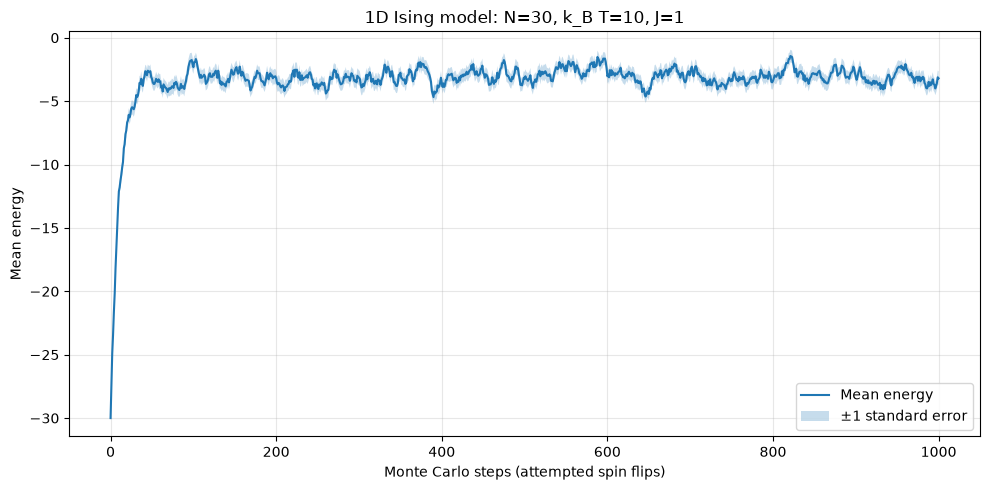

In [3]:
plt.figure(figsize=(10, 5))
plt.plot(steps, mean_energy, label="Mean energy")
plt.fill_between(steps, mean_energy - monte_carlo_error,
                 mean_energy + monte_carlo_error, alpha=0.25,
                 label="±1 standard error")
plt.xlabel("Monte Carlo steps (attempted spin flips)")
plt.ylabel("Mean energy")
plt.title(f"1D Ising model: N={N}, k_B T={k_B*T:g}, J={J:g}")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## Monte Carlo standard error

This is the standard error of the ensemble mean across independent runs at each step; it is **not** an estimate of the autocorrelation-adjusted uncertainty of a single long Markov chain.

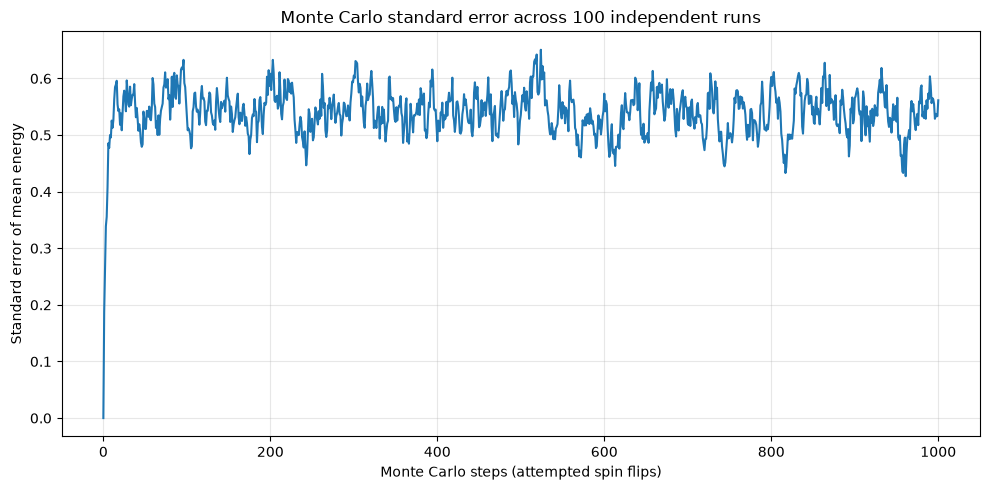

In [4]:
plt.figure(figsize=(10, 5))
plt.plot(steps, monte_carlo_error)
plt.xlabel("Monte Carlo steps (attempted spin flips)")
plt.ylabel("Standard error of mean energy")
plt.title(f"Monte Carlo standard error across {n_runs} independent runs")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## Quick correctness check

In [5]:
assert ising_energy(np.ones(N, dtype=int), J) == -J * N
assert np.all(energies >= -J * N - 1e-10)
assert np.all(energies <= J * N + 1e-10)
print("Energy bounds and aligned-state checks passed.")

Energy bounds and aligned-state checks passed.
